In [1]:
import sys
from pathlib import Path
import torch
sys.path.insert(0, str(Path.cwd().resolve().parents[1]))
from MoE_Optimization.common.clustering_utils import MMLUBatchGenerator





In [2]:
from transformers import AutoTokenizer, BitsAndBytesConfig
from transformers import AutoTokenizer, AutoModelForCausalLM

from MoE_Optimization.common.clustering_utils import get_qwen


MODEL = "Qwen/Qwen1.5-MoE-A2.7B"


quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,

    bnb_4bit_compute_dtype=torch.float16,  # Compute in float16 for speed
    bnb_4bit_use_double_quant=True,  # Double quantization for extra memory savings
    # Normalized float 4-bit (optimal for LLMs)
    bnb_4bit_quant_type="nf4"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL, trust_remote_code=True,
                                            device_map='cuda:2',
                                            )
model = AutoModelForCausalLM.from_pretrained(MODEL, trust_remote_code=True,
                                            device_map='cuda:2',
                                            dtype=torch.float16,
                                            quantization_config=quantization_config,
                                            cache_dir="../../.cache"
                                            )

Loading weights:   0%|          | 0/387 [00:00<?, ?it/s]

In [3]:
from MoE_Optimization.common.clustering_utils import SELECTED_TASKS, convert_inputs_to_tokens
from MoE_Optimization.common.expert_clusterer import ExpertClusterer


gen = MMLUBatchGenerator(subjects=SELECTED_TASKS, split='validation', batch_size=16, include_metadata=False)
example_inputs = convert_inputs_to_tokens(gen, tokenizer, model.device)
clusterer = ExpertClusterer(model, example_inputs)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Initialized MMLU batch generator with 5 subjects
Split: validation, Batch size: 16

📚 Loading subject 1/5: anatomy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 14 questions

📚 Loading subject 2/5: machine_learning


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions

📚 Loading subject 3/5: management


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions

📚 Loading subject 4/5: philosophy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 16 questions

📚 Loading subject 5/5: world_religions
  ✓ Created batch with 16 questions


In [4]:
from MoE_Optimization.common.moe_utils import discover_moe_layers


layers = discover_moe_layers(model)
layers

[MoeHandle(layer_idx=0, moe=Qwen2MoeSparseMoeBlock(
   (gate): Qwen2MoeTopKRouter()
   (experts): Qwen2MoeExperts(
     (act_fn): SiLUActivation()
   )
   (shared_expert): Qwen2MoeMLP(
     (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (down_proj): Linear4bit(in_features=5632, out_features=2048, bias=False)
     (act_fn): SiLUActivation()
   )
   (shared_expert_gate): Linear4bit(in_features=2048, out_features=1, bias=False)
 ), gate=Qwen2MoeTopKRouter(), experts=Qwen2MoeExperts(
   (act_fn): SiLUActivation()
 ), kind='qwen'),
 MoeHandle(layer_idx=1, moe=Qwen2MoeSparseMoeBlock(
   (gate): Qwen2MoeTopKRouter()
   (experts): Qwen2MoeExperts(
     (act_fn): SiLUActivation()
   )
   (shared_expert): Qwen2MoeMLP(
     (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (down_proj): Lin

In [5]:

handles2clusters = clusterer.create_clusters_by_PI([layers[0], layers[1]])

In [6]:
handles2clusters[0]

[[24, 40, 53],
 [43, 16, 58],
 [11, 17],
 [18, 39],
 [2, 28],
 [20, 21],
 [37, 6, 38],
 [35, 42, 47],
 [41, 54],
 [44, 49],
 [55, 3],
 [19, 50],
 [22, 26],
 [23, 25],
 [27, 29],
 [51, 0],
 [30, 10],
 [46, 48],
 [9, 7],
 [8, 32],
 [34, 1],
 [45, 31],
 [56, 5],
 [33, 14],
 [15, 13],
 [59, 52],
 [12, 4],
 [57, 36]]

Для сравнения оригинальное распределение популярности экспертов в слое 0
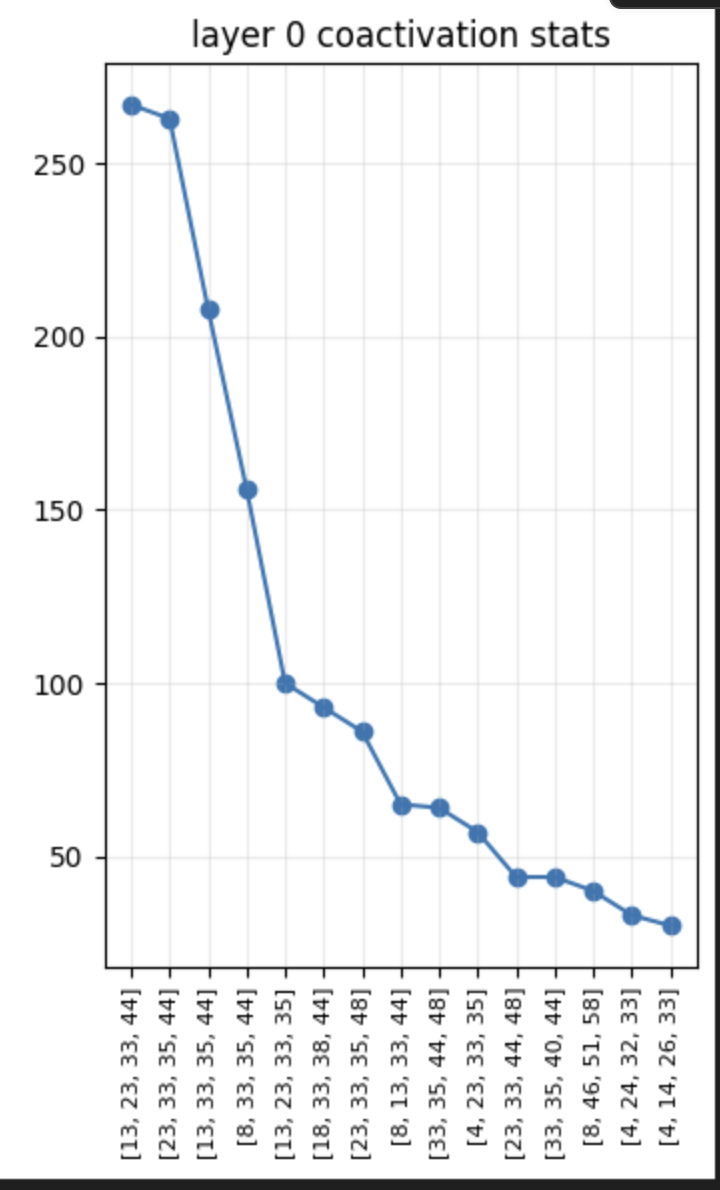

In [7]:
name2activations = clusterer._get_activations_from_gate([layers[0]])
clusters_0, history_0 = clusterer.create_clusters_by_PI_one_layer(layers[0], name2activations.items().__iter__().__next__()[1], log_history=True)

In [8]:
import matplotlib.pyplot as plt
import numpy as np

def plot_history_pi_drop(history, title="Average PI / EC during sequential cuts", pi_and_ec_mat_changed=False):
    if not history:
        print("History is empty")
        return

    steps = [row["step"] for row in history]

    pi_vals = [row["total_metric_after_split"] for row in history]
    # ec_vals = [row["total_ec_after_split"] for row in history]
    ec_vals = []
    if (pi_and_ec_mat_changed):
        pi_vals, ec_vals = ec_vals, pi_vals

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    # График PI сверху
    ax1.plot(steps, pi_vals, marker="o", color="tab:blue", linewidth=2)
    ax1.set_title("PI (Pairwise Inclusion)", fontsize=12)
    ax1.set_ylabel("mean PI across active clusters")
    ax1.grid(True, alpha=0.3)
    
    # График EC снизу
    if not np.all(np.isnan(ec_vals)):
        ax2.plot(steps, ec_vals, marker="o", color="tab:orange", linewidth=2)
    ax2.set_title("EC (Exclusive Communication)", fontsize=12)
    ax2.set_xlabel("Split step")
    ax2.set_ylabel("mean EC across active clusters")
    ax2.grid(True, alpha=0.3)

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

In [9]:
history_0

[{'step': 1,
  'divided_cluster': [0,
   1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34,
   35,
   36,
   37,
   38,
   39,
   40,
   41,
   42,
   43,
   44,
   45,
   46,
   47,
   48,
   49,
   50,
   51,
   52,
   53,
   54,
   55,
   56,
   57,
   58,
   59],
  'left': [33,
   8,
   37,
   43,
   3,
   1,
   2,
   55,
   18,
   21,
   16,
   32,
   45,
   39,
   17,
   31,
   11,
   58,
   6,
   56,
   34,
   38,
   9,
   7,
   14,
   20,
   5,
   50,
   28,
   19],
  'right': [54,
   0,
   49,
   26,
   47,
   29,
   15,
   30,
   59,
   22,
   42,
   36,
   12,
   27,
   24,
   41,
   25,
   40,
   46,
   48,
   51,
   57,
   52,
   53,
   10,
   4,
   13,
   35,
   23,
   44],
  'all_clusters': [[33,
    8,
    37,
    43,
    3,
    1,
    2,
    55,
    18,
    21,
    16,
    32,
    45,
    39,
    

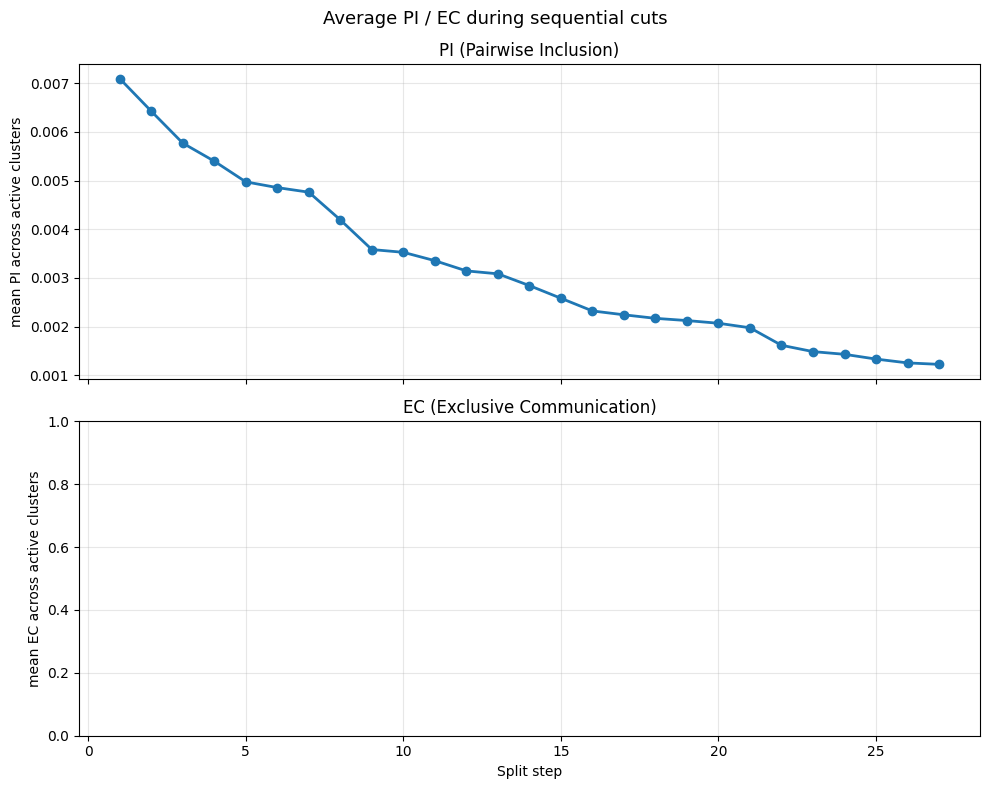

In [10]:
plot_history_pi_drop(history_0)

In [11]:
from MoE_Optimization.common.expert_logger_data_converter import ExpertLoggerDataConverter
from MoE_Optimization.common.expert_matcher import ExpertMatcher


name2activations = clusterer._get_activations_from_gate([layers[0]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[0]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True)

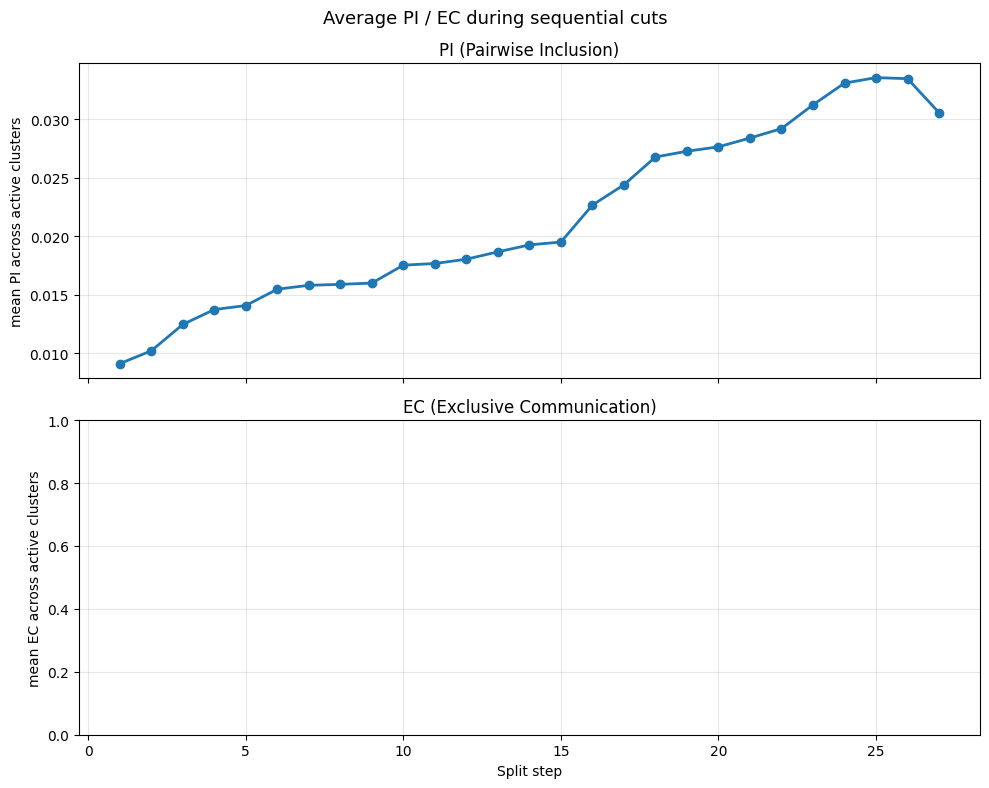

In [12]:
plot_history_pi_drop(history)

Correctness checked! Maximize and minimize works fine.

New cases

In [14]:
front_points_result = clusterer._create_clusters_by(clusterer.create_clusters_by_PI_front_points, [layers[0]])

In [21]:
print("the amount of different clusterings", front_points_result[0].__len__())
print("first one")
print(front_points_result[0][0])

the amount of different clusterings 4
first one
[[8, 52, 3, 21, 49, 25, 2, 46, 32, 0, 36, 34, 17, 13, 56, 9, 59, 55, 35, 37, 5, 23, 28, 58, 19, 6, 12, 44, 14, 33], [29, 7, 24], [20, 11, 51, 50, 39, 18, 22], [26, 53], [15, 27], [43, 40, 10, 4], [42, 54, 16, 57], [41, 47, 45, 30], [31, 48, 1, 38]]
